In [40]:
# Activate virtual environment (to enter in terminal)
# .\.venv\Scripts\activate

In [41]:
# Install all required packages from requirements.txt
%pip install -r ../requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [42]:
import geopandas as gpd
import pandas as pd
import os

# --- Define the correct relative path to your data ---
base_data_path = '../data/raw/environmental_data'

# --- Initialize two separate lists for the datasets ---
sis_gdfs = []
osaka_gdfs = []

print(f"Searching for shapefiles in: {os.path.abspath(base_data_path)}\n")

# Use os.walk() to go through all subdirectories
for dirpath, dirnames, filenames in os.walk(base_data_path):
    if 'output.shp' in filenames:
        folder_name = os.path.basename(dirpath)
        
        # --- Extract info and determine the dataset source ---
        try:
            parts = folder_name.split('_')
            year = int(parts[0])
            source_key = parts[1].upper() # Use upper() for case-insensitivity ('SIS', 'OSAKA')
        except (ValueError, IndexError):
            print(f"Could not parse folder name '{folder_name}'. Skipping.")
            continue
            
        shp_filepath = os.path.join(dirpath, 'output.shp')
        gdf_temp = gpd.read_file(shp_filepath)
        gdf_temp['year'] = year
        
        # --- Add the GeoDataFrame to the correct list ---
        if 'SIS' in source_key:
            gdf_temp['source'] = 'SIS'
            sis_gdfs.append(gdf_temp)
            print(f"Loaded SIS data: {folder_name}")
        elif 'OSAKA' in source_key:
            gdf_temp['source'] = 'Osaka'
            osaka_gdfs.append(gdf_temp)
            print(f"Loaded Osaka data: {folder_name}")
        else:
            print(f"Source not recognized in '{folder_name}'. Skipping.")

# --- Combine the lists into two separate master GeoDataFrames ---

# Seto Inland Sea (SIS) DataFrame
if sis_gdfs:
    sis_gdf = pd.concat(sis_gdfs, ignore_index=True)
    print("\n✅ Seto Inland Sea (SIS) DataFrame created successfully!")
    print("-----------------------------------------------------")
    print(f"Total rows: {len(sis_gdf)}")
    print(f"Detected years: {sis_gdf['year'].unique()}")
    print("Data Preview:")
    print(sis_gdf.head())
else:
    print("\nℹ️ No SIS data was found.")

# Osaka DataFrame
if osaka_gdfs:
    osaka_gdf = pd.concat(osaka_gdfs, ignore_index=True)
    print("\n✅ Osaka DataFrame created successfully!")
    print("--------------------------------------")
    print(f"Total rows: {len(osaka_gdf)}")
    print(f"Detected years: {osaka_gdf['year'].unique()}")
    print("Data Preview:")
    print(osaka_gdf.head())
else:
    print("\nℹ️ No Osaka data was found.")

Searching for shapefiles in: c:\Users\reyha\Documents\Master\東京大学\Colleag season 2\Masters thesis\Seto_Inland_sea_Analysis\data\raw\environmental_data

Loaded SIS data: 1981_SIS_wq-raw
Loaded SIS data: 1982_SIS_wq-raw
Loaded SIS data: 1983_SIS_wq-raw
Loaded SIS data: 1984_SIS_wq-raw
Loaded SIS data: 1985_SIS_wq-raw
Loaded SIS data: 1986_SIS_wq-raw
Loaded SIS data: 1987_SIS_wq-raw
Loaded SIS data: 1988_SIS_wq-raw
Loaded SIS data: 1989_SIS_wq-raw
Loaded SIS data: 1990_SIS_wq-raw
Loaded SIS data: 1991_SIS_wq-raw
Loaded SIS data: 1992_SIS_wq-raw
Loaded SIS data: 1993_SIS_wq-raw
Loaded SIS data: 1994_SIS_wq-raw
Loaded SIS data: 1995_SIS_wq-raw
Loaded SIS data: 1996_SIS_wq-raw
Loaded SIS data: 1997_SIS_wq-raw
Loaded SIS data: 1998_SIS_wq-raw
Loaded SIS data: 1999_SIS_wq-raw
Loaded SIS data: 2000_SIS_wq-raw
Loaded SIS data: 2001_SIS_wq-raw
Loaded SIS data: 2002_SIS_wq-raw
Loaded SIS data: 2003_SIS_wq-raw
Loaded SIS data: 2004_SIS_wq-raw
Loaded SIS data: 2005_SIS_wq-raw
Loaded SIS data: 2006_S

Plotting 924 data points for the year 2022.


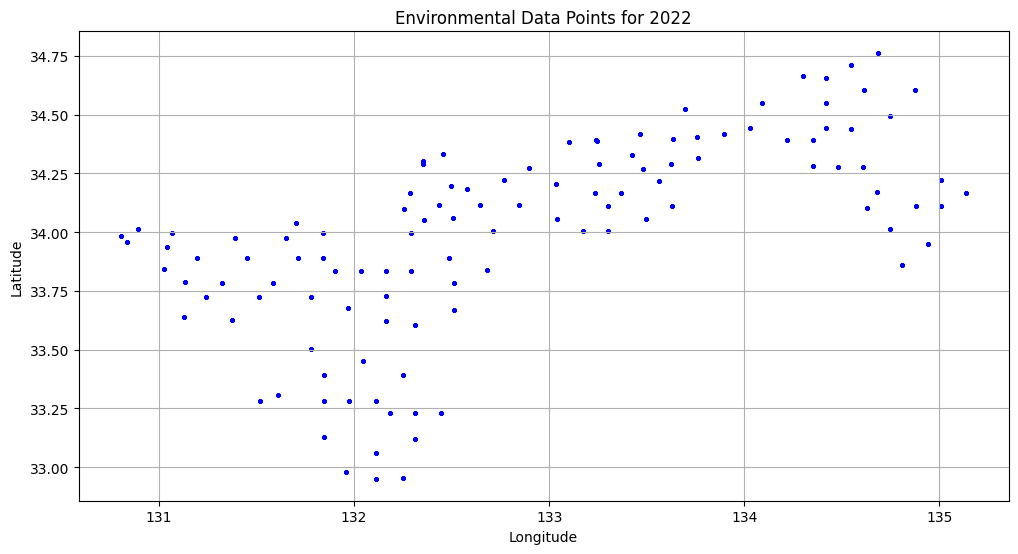

In [43]:
# Simple plotting test

import matplotlib.pyplot as plt

# --- 1. Choose a year to display ---
# You can change this to any year present in your dataset.
year_to_plot = 2022 

# --- 2. Filter the GeoDataFrame for that year ---
# We'll use the 'sis_gdf' DataFrame as an example.
# This creates a new GeoDataFrame containing only the data from the selected year.
single_year_gdf = sis_gdf[sis_gdf['year'] == year_to_plot]

print(f"Plotting {len(single_year_gdf)} data points for the year {year_to_plot}.")

# --- 3. Create the plot ---
# You can customize the figure size, marker style, and color.
fig, ax = plt.subplots(1, 1, figsize=(12, 12))

single_year_gdf.plot(
    ax=ax,
    marker='o',
    color='blue',
    markersize=5
)

# --- 4. Add titles and labels for context ---
ax.set_title(f'Environmental Data Points for {year_to_plot}')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.grid(True)

# --- 5. Show the plot ---
plt.show()

In [44]:
# Plotting on map with Cartopy

import matplotlib.pyplot as plt
import cartopy.crs as ccrs# Add this before you use sis_gdf
import geopandas as gpd
import cartopy.feature as cfeature

sis_gdf = gpd.read_file('../data/raw/environmental_data/2022_SIS_wq-raw/output.shp')
print(sis_gdf.columns)


Index(['uniqueid', 'zettaicode', 'locationna', 'wancode', 'prefectuei',
       'watercode', 'renban', 'nendo', 'survey_ym', 'surveyyear', 'surveymont',
       'surveyday', 'surveyhour', 'surveymini', 'saisuipoin', 'latitude',
       'longitude', 'weather', 'cloud', 'fuko', 'fusoku', 'temp', 'color',
       'saisuidept', 'depth', 'clearness', 'wtemp', 'ph', 'ph2', 'do_', 'do_2',
       'salt', 'salt2', 'cod', 'cod2', 'rcod', 'rcod2', 'nh4n', 'nh4n2',
       'no2n', 'no2n2', 'no3n', 'no3n2', 'tn', 'tn2', 'po4p', 'po4p2', 'tp',
       'tp2', 'chlorophyl', 'chloroph_1', 'feiochin', 'feiochin2', 'toc',
       'toc2', 'doc', 'doc2', 'dataflag', 'scale', 'geometry'],
      dtype='object')


Successfully loaded POLYLINE.shp
Columns in the shapefile: Index(['uniqueid', 'zettaicode', 'locationna', 'wancode', 'prefectuei',
       'watercode', 'renban', 'nendo', 'survey_ym', 'surveyyear', 'surveymont',
       'surveyday', 'surveyhour', 'surveymini', 'saisuipoin', 'latitude',
       'longitude', 'weather', 'cloud', 'fuko', 'fusoku', 'temp', 'color',
       'saisuidept', 'depth', 'clearness', 'wtemp', 'ph', 'ph2', 'do_', 'do_2',
       'salt', 'salt2', 'cod', 'cod2', 'rcod', 'rcod2', 'nh4n', 'nh4n2',
       'no2n', 'no2n2', 'no3n', 'no3n2', 'tn', 'tn2', 'po4p', 'po4p2', 'tp',
       'tp2', 'chlorophyl', 'chloroph_1', 'feiochin', 'feiochin2', 'toc',
       'toc2', 'doc', 'doc2', 'dataflag', 'scale', 'geometry'],
      dtype='object')

Loaded 924 data points for the year 2022.


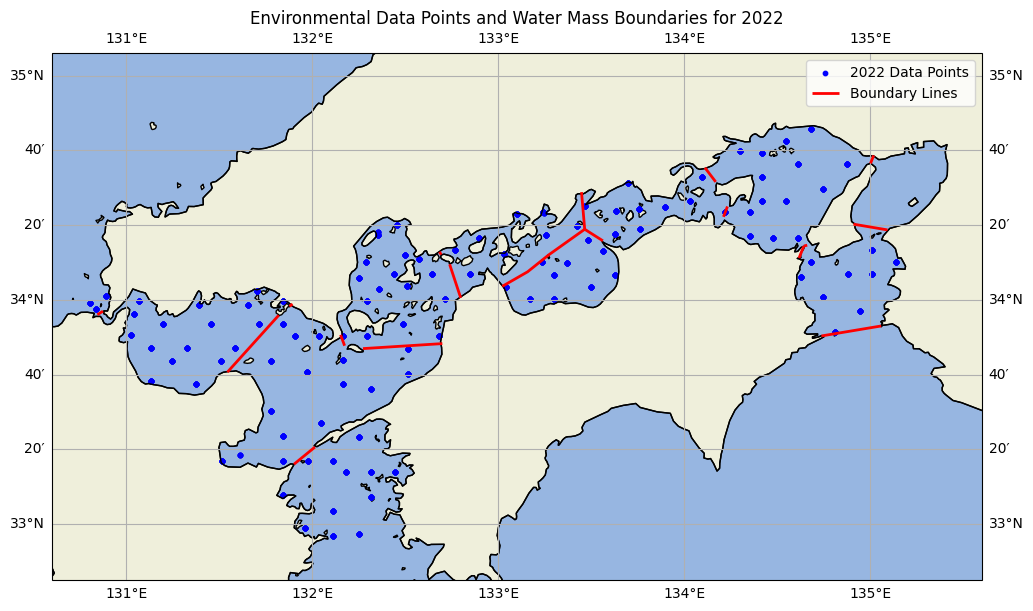

In [45]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import geopandas as gpd
import cartopy.feature as cfeature

# The year is known from the folder name
year_to_plot = 2022

# --- NEW: Load the boundary lines shapefile ---
try:
    # IMPORTANT: Update this path to where your POLYLINE.shp is located
    lines_gdf = gpd.read_file('../data/boundaries/SIS water mass boundaries/POLYLINE.shp')
    print("Successfully loaded POLYLINE.shp")
except Exception as e:
    print(f"Could not load POLYLINE.shp. Error: {e}")
    # Create an empty GeoDataFrame if the file is not found, so the script can run
    lines_gdf = gpd.GeoDataFrame(geometry=[])

# Load the shapefile for the single year
sis_gdf = gpd.read_file('../data/raw/environmental_data/2022_SIS_wq-raw/output.shp')
print("Columns in the shapefile:", sis_gdf.columns)
print(f"\nLoaded {len(sis_gdf)} data points for the year {year_to_plot}.")

# --- This is the corrected part ---
# The filtering line has been removed, as sis_gdf already contains only 2022 data.

# --- 2. Create a map using Cartopy ---
fig = plt.figure(figsize=(12, 10))
ax = plt.axes(projection=ccrs.PlateCarree())

# --- 3. Set the geographic extent ---
ax.set_extent([130.6, 135.6, 32.75, 35.1], crs=ccrs.PlateCarree())

# --- 4. Add geographic features ---
ax.add_feature(cfeature.OCEAN)
ax.add_feature(cfeature.LAND, edgecolor='black')
ax.add_feature(cfeature.COASTLINE)
ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)

# --- 5. Plot your data points directly from sis_gdf ---
ax.scatter(
    sis_gdf.geometry.x,  # Changed to sis_gdf
    sis_gdf.geometry.y,  # Changed to sis_gdf
    transform=ccrs.PlateCarree(),
    color='blue',
    marker='o',
    s=10,
    label=f'{year_to_plot} Data Points'
)

# --- NEW: Plot the boundary lines on the same map ---
if not lines_gdf.empty:
    lines_gdf.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        color='red',
        linewidth=2,
        label='Boundary Lines',
        zorder=2 # Lower zorder, so lines are below points
    )


ax.set_title(f'Environmental Data Points and Water Mass Boundaries for {year_to_plot}')
ax.legend()
plt.show()

Loaded 924 data points for 2022.
Loaded 1 water mass polygons.
CRS mismatch found. Converting polygons to match points data CRS...


c:\Users\reyha\Documents\Master\東京大学\Colleag season 2\Masters thesis\Seto_Inland_sea_Analysis\.venv\Lib\site-packages\pyogrio\raw.py:198: RuntimeWarning: ../data/boundaries/SIS water mass polygon/POLYGON.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(
C:\Users\reyha\AppData\Local\Temp\ipykernel_28600\1414884230.py:64: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend()


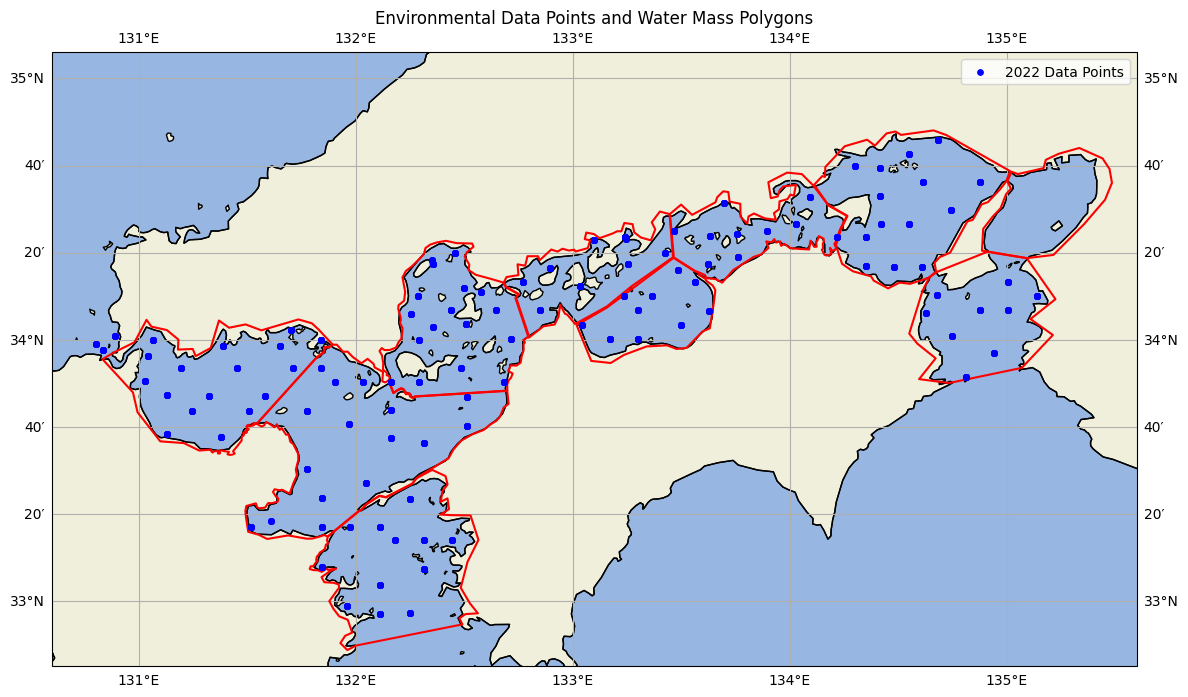

In [46]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import geopandas as gpd
import cartopy.feature as cfeature

# --- 1. Load your data files ---

# Load the sampling points shapefile
sis_gdf = gpd.read_file('../data/raw/environmental_data/2022_SIS_wq-raw/output.shp')
year_to_plot = 2022
print(f"Loaded {len(sis_gdf)} data points for {year_to_plot}.")

# Load your new polygon shapefile
try:
    # Use the exact path you provided, adding '../' to navigate from the 'notebooks' folder
    polygons_gdf = gpd.read_file('../data/boundaries/SIS water mass polygon/POLYGON.shp')
    
    print(f"Loaded {len(polygons_gdf)} water mass polygons.")
except Exception as e:
    print(f"Could not load POLYGON.shp. Error: {e}")
    polygons_gdf = gpd.GeoDataFrame(geometry=[])

# --- 2. CRITICAL: Check and match the Coordinate Reference System (CRS) ---
if not polygons_gdf.empty and sis_gdf.crs != polygons_gdf.crs:
    print("CRS mismatch found. Converting polygons to match points data CRS...")
    polygons_gdf = polygons_gdf.to_crs(sis_gdf.crs)

# --- 3. Create a map using Cartopy ---
fig = plt.figure(figsize=(14, 12))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([130.6, 135.6, 32.75, 35.1], crs=ccrs.PlateCarree())

# --- 4. Add geographic features (land, ocean) ---
ax.add_feature(cfeature.OCEAN, zorder=0)
ax.add_feature(cfeature.LAND, edgecolor='black', zorder=1)
ax.add_feature(cfeature.COASTLINE, zorder=1)
ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)

# --- 5. Plot your new polygons ---
if not polygons_gdf.empty:
    polygons_gdf.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        edgecolor='red',      # Color for the boundary lines
        facecolor='none',     # Makes the polygons transparent
        linewidth=1.5,
        label='Water Mass Boundaries',
        zorder=2
    )

# --- 6. Plot your sampling points on top ---
ax.scatter(
    sis_gdf.geometry.x,
    sis_gdf.geometry.y,
    transform=ccrs.PlateCarree(),
    color='blue',
    marker='o',
    s=15,
    label=f'{year_to_plot} Data Points',
    zorder=3 # Higher zorder means it's drawn on top
)

ax.set_title('Environmental Data Points and Water Mass Polygons')
ax.legend()
plt.show()

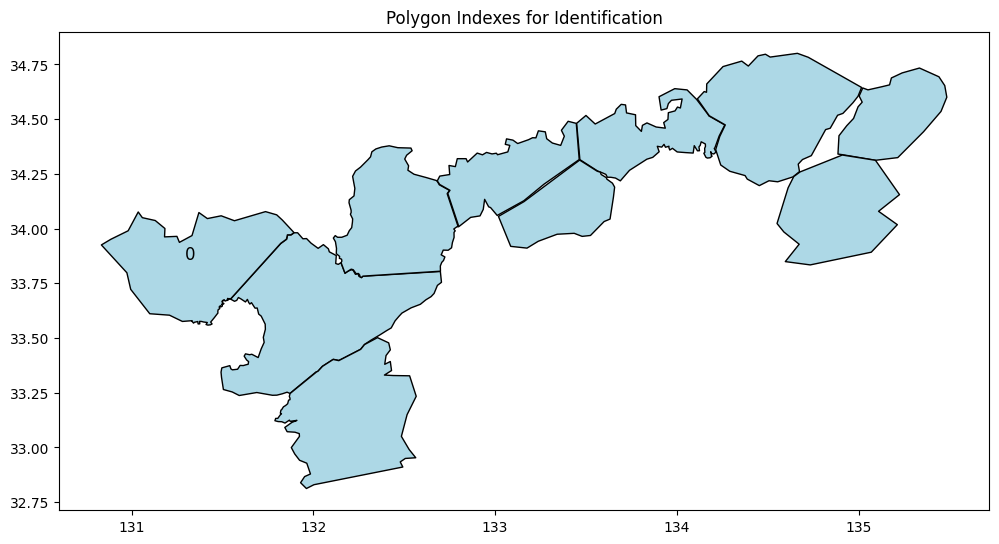

In [47]:
# This assumes 'polygons_gdf' is already loaded from the previous step.

# Create a plot
fig, ax = plt.subplots(1, 1, figsize=(12, 10))
polygons_gdf.plot(ax=ax, edgecolor='black', facecolor='lightblue')

# Add index labels to the center of each polygon
for idx, row in polygons_gdf.iterrows():
    # The representative_point() method safely finds a point within the polygon
    centroid = row.geometry.representative_point()
    ax.text(centroid.x, centroid.y, str(idx), fontsize=12, ha='center')

ax.set_title('Polygon Indexes for Identification')
plt.show()

After exploding, the GeoDataFrame now has 10 features.


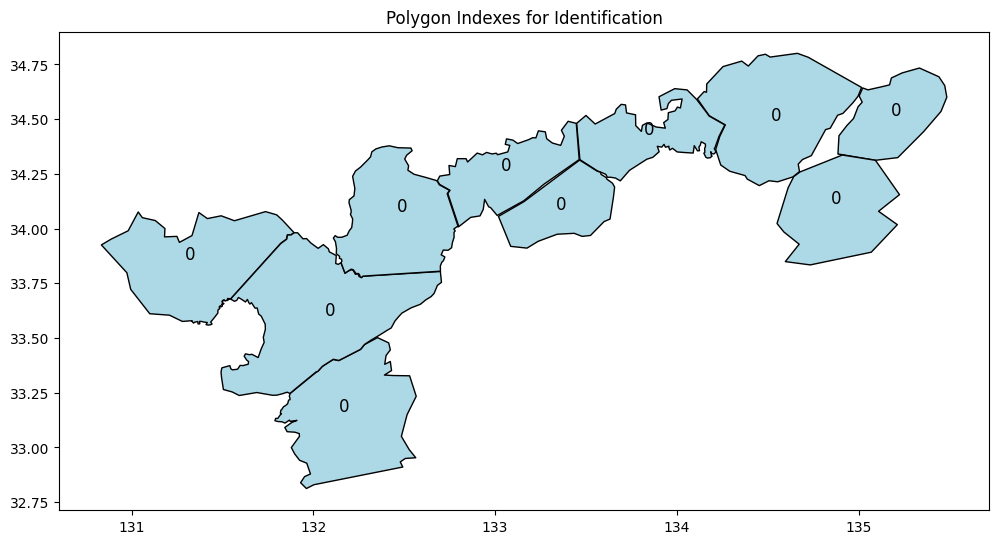

In [48]:
# This script assumes 'polygons_gdf' is already loaded from the previous step.

# --- 1. Explode the MultiPolygon into individual Polygons ---
# This converts the single row with many shapes into many rows, each with one shape.
# The original GeoDataFrame will be overwritten with the corrected version.
polygons_gdf = polygons_gdf.explode(index_parts=False)

print(f"After exploding, the GeoDataFrame now has {len(polygons_gdf)} features.")


# --- 2. Plot the polygons again to identify their indexes ---
fig, ax = plt.subplots(1, 1, figsize=(12, 10))
polygons_gdf.plot(ax=ax, edgecolor='black', facecolor='lightblue')

# Add index labels to the center of each polygon
for idx, row in polygons_gdf.iterrows():
    # The representative_point() method safely finds a point within the polygon
    centroid = row.geometry.representative_point()
    ax.text(centroid.x, centroid.y, str(idx), fontsize=12, ha='center', color='black')

ax.set_title('Polygon Indexes for Identification')
plt.show()

After exploding and resetting the index, the GeoDataFrame now has 10 features.
Here's a preview of the corrected data:
                                            geometry
0  POLYGON ((132.49228 32.90961, 132.4781 32.9329...
1  POLYGON ((131.54398 33.67764, 131.82047 33.932...
2  POLYGON ((132.69881 33.80356, 132.27295 33.781...
3  POLYGON ((134.67492 34.26026, 134.66784 34.294...
4  POLYGON ((134.20923 34.36868, 134.2326 34.4226...


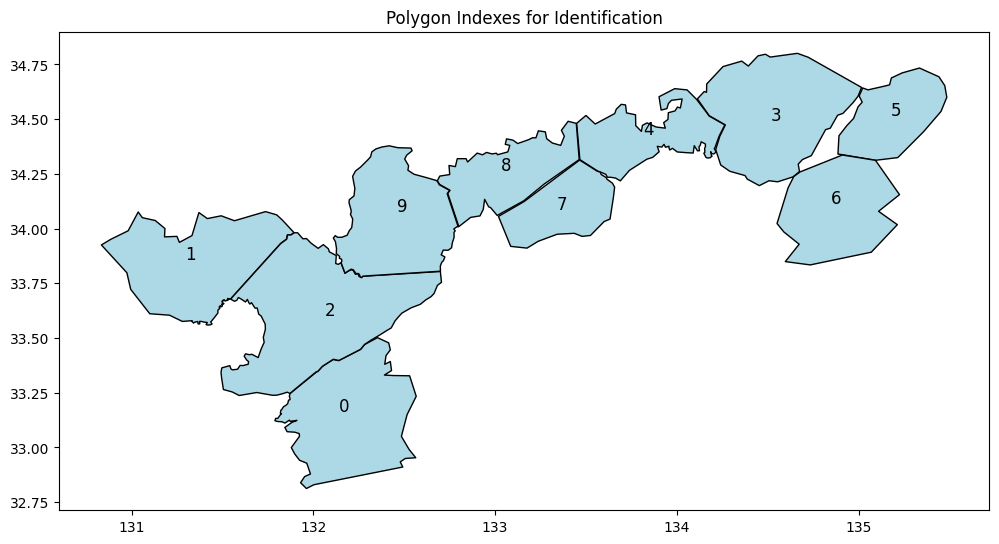

In [49]:
# This script assumes 'polygons_gdf' is still loaded as the single MultiPolygon feature.

# --- 1. Explode the MultiPolygon into individual Polygons ---
polygons_gdf = polygons_gdf.explode(index_parts=False)

# --- 2. THE FIX: Reset the index to be unique and sequential (0, 1, 2, ...) ---
polygons_gdf = polygons_gdf.reset_index(drop=True)

print(f"After exploding and resetting the index, the GeoDataFrame now has {len(polygons_gdf)} features.")
print("Here's a preview of the corrected data:")
print(polygons_gdf.head())


# --- 3. Plot the polygons again to identify their unique indexes ---
fig, ax = plt.subplots(1, 1, figsize=(12, 10))
polygons_gdf.plot(ax=ax, edgecolor='black', facecolor='lightblue')

# Add index labels to the center of each polygon
for idx, row in polygons_gdf.iterrows():
    centroid = row.geometry.representative_point()
    ax.text(centroid.x, centroid.y, str(idx), fontsize=12, ha='center', color='black')

ax.set_title('Polygon Indexes for Identification')
plt.show()

In [ ]:
# IMPORTANT: You must fill this list with the numbers from your reference map,
# making sure the order matches the current indexes (0, 1, 2, ...) from your plot.

# The length of this list MUST match the number of polygons you have.
area_numbers = [
    10,  
    9,  
    8,  
    3,
    4,    
    2,  
    1,  
    5,  
    6,  
    7  
]

# Add this list as a new column named 'area_num'
polygons_gdf['area_num'] = area_numbers

# Assign the names as well, in the same order
area_names = [
    'Bungo Channel',       # Corresponds to index 0
    'Suo Nada',       # Corresponds to index 1
    'Iyo Nada',    # Corresponds to index 2
    'Harima Nada',     # Corresponds to index 3
    'Bisan Seto',     # Corresponds to index 4
    'Osaka Bay',        # Corresponds to index 5
    'Kii Channel',         # Corresponds to index 6
    'Hiuchi Nada',        # Corresponds to index 7
    'Bingo Nada', # Corresponds to index 8
    'Aki Nada'        # Corresponds to index 9
]
polygons_gdf['name'] = area_names


# Verify the result. You should see the new 'area_num' and 'name' columns.
print("GeoDataFrame is now updated with area numbers and names:")
print(polygons_gdf.head())

GeoDataFrame is now updated with area numbers and names:
                                            geometry  area_num           name
0  POLYGON ((132.49228 32.90961, 132.4781 32.9329...        10  Bungo Channel
1  POLYGON ((131.54398 33.67764, 131.82047 33.932...         9       Suo Nada
2  POLYGON ((132.69881 33.80356, 132.27295 33.781...         8       Iyo Nada
3  POLYGON ((134.67492 34.26026, 134.66784 34.294...         3    Harima Nada
4  POLYGON ((134.20923 34.36868, 134.2326 34.4226...         4     Bisan Seto


In [51]:
# This script assumes 'sis_gdf' and the now-named 'polygons_gdf' are loaded.

# --- 1. Perform the Spatial Join ---
# This merges the two GeoDataFrames based on their spatial relationship.
# It keeps only the points that are 'within' one of the polygons.
joined_gdf = gpd.sjoin(sis_gdf, polygons_gdf, how="inner", predicate="within")


# --- 2. Check the Result ---
print("\nSpatial join complete! Here are the first few rows of the new dataset:")
# Note the new 'name' and 'index_right' columns at the end
print(joined_gdf.head())


# --- 3. Verify by Counting Points in Each Water Mass ---
# This is the best way to see a summary of the results.
print("\nNumber of sampling points assigned to each water mass:")
print(joined_gdf['name'].value_counts())



Spatial join complete! Here are the first few rows of the new dataset:
     uniqueid zettaicode locationna wancode prefectuei watercode renban  \
0  0000067171   00038372     愛媛県372      04         38       311    372   
1  0000067191   00038666     愛媛県666      04         38       317    666   
2  0000067386   00044528     大分県528      04         44       314    528   
3  0000067387   00044528     大分県528      04         44       314    528   
4  0000066527   00028119     兵庫県119      04         28       305    119   

   nendo  survey_ym  surveyyear  ...   toc  toc2   doc  doc2  dataflag  scale  \
0   2022 2022-03-01        2022  ...  None   0.0  None   0.0         1     -1   
1   2022 2022-03-01        2022  ...  None   0.0  None   0.0         1     -1   
2   2022 2022-06-01        2022  ...  None   0.0  None   0.0         1     -1   
3   2022 2022-06-01        2022  ...  None   0.0  None   0.0         1     -1   
4   2022 2022-03-01        2022  ...   1.1   1.1   0.9   0.9         1  

Text(0.5, 1.0, 'Sampling Points Colored by Assigned Water Mass')

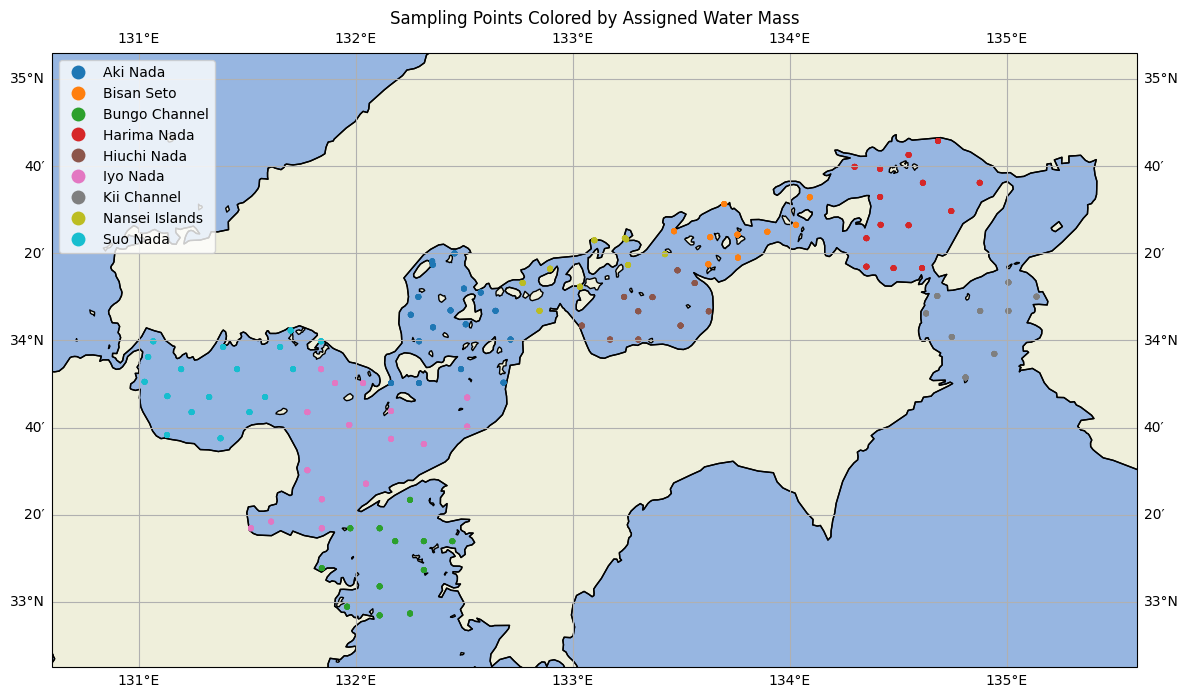

In [52]:
# Plot the new joined GeoDataFrame
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

fig = plt.figure(figsize=(14, 12))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([130.6, 135.6, 32.75, 35.1], crs=ccrs.PlateCarree())

# --- 4. Add geographic features (land, ocean) ---
ax.add_feature(cfeature.OCEAN, zorder=0)
ax.add_feature(cfeature.LAND, edgecolor='black', zorder=1)
ax.add_feature(cfeature.COASTLINE, zorder=1)
ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)

joined_gdf.plot(column='name', ax=ax, legend=True, markersize=10)
ax.set_title('Sampling Points Colored by Assigned Water Mass')
